In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

for file in drive_root.rglob("streetguard_potholes.zip"):
    print(file)

/content/drive/MyDrive/YOLO StreetGuard AI/streetguard_potholes.zip


In [3]:
from pathlib import Path
import zipfile

# Update this path if Colab printed a different ZIP location
ZIP_PATH = Path(
    "/content/drive/MyDrive/YOLO StreetGuard AI/streetguard_potholes.zip"
)

EXTRACT_DIR = Path("/content/streetguard_dataset")

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP file not found: {ZIP_PATH}\n"
        "Replace ZIP_PATH with the path printed in Step 7."
    )

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Extraction location:", EXTRACT_DIR)

# Locate the dataset configuration
yaml_files = list(EXTRACT_DIR.rglob("data.yaml"))

for yaml_file in yaml_files:
    print("Dataset YAML:", yaml_file)

Dataset extracted successfully!
Extraction location: /content/streetguard_dataset
Dataset YAML: /content/streetguard_dataset/potholes/data.yaml


In [4]:
from pathlib import Path

DATASET_DIR = Path("/content/streetguard_dataset/potholes")

for split in ["train", "val", "test"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = (
        sum(1 for p in image_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"])
        if image_dir.exists() else 0
    )

    labels = (
        sum(1 for p in label_dir.glob("*.txt"))
        if label_dir.exists() else 0
    )

    print(f"{split.upper()}: {images} images, {labels} label files")

TRAIN: 479 images, 479 label files
VAL: 52 images, 52 label files
TEST: 133 images, 133 label files


In [5]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ))
else:
    print("No CUDA GPU detected. Check your Colab runtime settings.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


In [6]:
%pip install -q ultralytics

In [7]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.189


In [8]:
from pathlib import Path

DATASET_DIR = Path("/content/streetguard_dataset/potholes")
yaml_path = DATASET_DIR / "data.yaml"

print("YAML exists:", yaml_path.exists())

if yaml_path.exists():
    print(yaml_path.read_text())

YAML exists: True
path: D:/github patelharshil2288/yolo-streetguard-ai/data/processed/potholes
train: images/train
val: images/val
test: images/test
names:
  0: pothole



In [9]:
from pathlib import Path
import yaml

# Dataset location in Google Colab
DATASET_DIR = Path("/content/streetguard_dataset/potholes")
yaml_path = DATASET_DIR / "data.yaml"

# Load existing configuration
with yaml_path.open("r") as f:
    data = yaml.safe_load(f)

# Replace the Windows path with the Colab path
data["path"] = str(DATASET_DIR)

# Save the updated configuration
with yaml_path.open("w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(yaml_path.read_text())

path: /content/streetguard_dataset/potholes
train: images/train
val: images/val
test: images/test
names:
  0: pothole



In [10]:
from pathlib import Path
import yaml

yaml_path = Path("/content/streetguard_dataset/potholes/data.yaml")

with yaml_path.open("r") as f:
    data = yaml.safe_load(f)

root = Path(data["path"])

for split in ["train", "val", "test"]:
    image_dir = root / data[split]
    label_dir = root / "labels" / split

    assert image_dir.is_dir(), f"Missing image directory: {image_dir}"
    assert label_dir.is_dir(), f"Missing label directory: {label_dir}"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]
    labels = list(label_dir.glob("*.txt"))

    print(f"{split.upper()}: {len(images)} images, {len(labels)} labels")
    assert len(images) == len(labels), f"Count mismatch in {split}"

assert data["names"] == {0: "pothole"}, f"Unexpected class names: {data['names']}"

print("\nSUCCESS: Dataset paths and file counts verified.")

TRAIN: 479 images, 479 labels
VAL: 52 images, 52 labels
TEST: 133 images, 133 labels

SUCCESS: Dataset paths and file counts verified.


In [11]:
from ultralytics import YOLO
import torch
from pathlib import Path

# 1. Confirm GPU availability
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is unavailable. Check your Colab runtime settings."
    )

print("GPU:", torch.cuda.get_device_name(0))

# 2. Dataset configuration
DATA_YAML = "/content/streetguard_dataset/potholes/data.yaml"

if not Path(DATA_YAML).exists():
    raise FileNotFoundError(f"Dataset configuration not found: {DATA_YAML}")

# 3. Load pretrained YOLO11 nano weights
model = YOLO("yolo11n.pt")

# 4. Train the pothole detector
results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/streetguard_runs",
    name="streetguard_yolo11n",
    seed=42,
    plots=True,
    save=True
)

print("\nTraining finished.")
print("Best model:",
      "/content/streetguard_runs/streetguard_yolo11n/weights/best.pt")

GPU: Tesla T4
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/streetguard_dataset/potholes/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=streetguard_yolo11n, nbs=64,

In [12]:
from pathlib import Path

run_dir = Path(
    "/content/streetguard_runs/streetguard_yolo11n"
)

print("Training output directory:", run_dir)
print("\nAvailable result files:")

for file in sorted(run_dir.rglob("*")):
    if file.is_file():
        print(file.relative_to(run_dir))

Training output directory: /content/streetguard_runs/streetguard_yolo11n

Available result files:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch1200.jpg
train_batch1201.jpg
train_batch1202.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights/best.pt
weights/last.pt


In [13]:
from pathlib import Path
import shutil

best_model = Path(
    "/content/streetguard_runs/streetguard_yolo11n/weights/best.pt"
)

if not best_model.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {best_model}")

drive_output = Path(
    "/content/drive/MyDrive/YOLO StreetGuard AI/models"
)
drive_output.mkdir(parents=True, exist_ok=True)

destination = drive_output / "streetguard_yolo11n_best.pt"
shutil.copy2(best_model, destination)

print("Model saved successfully:")
print(destination)
print("Model size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))

Model saved successfully:
/content/drive/MyDrive/YOLO StreetGuard AI/models/streetguard_yolo11n_best.pt
Model size (MB): 5.25


In [14]:
from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = Path(
    "/content/drive/MyDrive/YOLO StreetGuard AI/models/"
    "streetguard_yolo11n_best.pt"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

model = YOLO(str(MODEL_PATH))

print("Model loaded successfully!")
print("Model file size (MB):", round(
    MODEL_PATH.stat().st_size / (1024 * 1024), 2
))
print("Model classes:", model.names)

Model loaded successfully!
Model file size (MB): 5.25
Model classes: {0: 'pothole'}


In [15]:
from ultralytics import YOLO

MODEL_PATH = (
    "/content/drive/MyDrive/YOLO StreetGuard AI/models/"
    "streetguard_yolo11n_best.pt"
)

DATA_YAML = "/content/streetguard_dataset/potholes/data.yaml"

model = YOLO(MODEL_PATH)

metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/streetguard_runs",
    name="streetguard_test_evaluation"
)

print("\n========== TEST RESULTS ==========")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@50:", metrics.box.map50)
print("mAP@50-95:", metrics.box.map)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2032.6±533.1 MB/s, size: 103.2 KB)
val: Scanning /content/streetguard_dataset/potholes/labels/test... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 2.1Kit/s 0.1s
val: New cache created: /content/streetguard_dataset/potholes/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 7.4it/s 2.3s
                   all        133        299      0.787      0.652      0.769      0.496
Speed: 2.2ms preprocess, 8.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/streetguard_runs/streetguard_test_evaluation

========== TEST RESULTS ==========
Precision: 0.7870117184533936
Recall: 0.6521739130434783
mAP@50: 0.7693320121909515
mAP@50-95: 0.49589763876619664


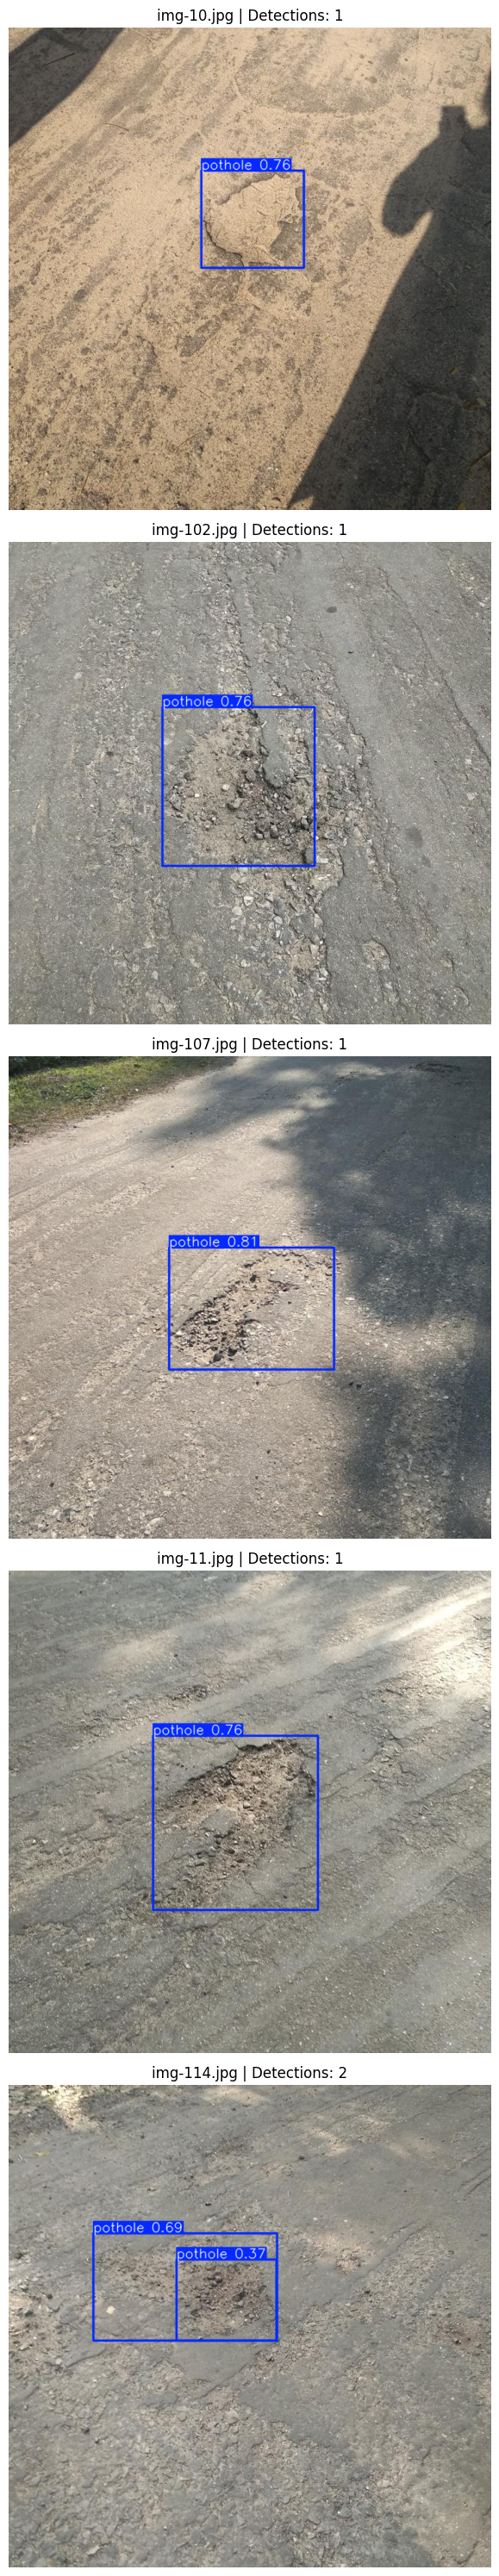

In [17]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

MODEL_PATH = (
    "/content/drive/MyDrive/YOLO StreetGuard AI/"
    "models/streetguard_yolo11n_best.pt"
)

TEST_DIR = Path(
    "/content/streetguard_dataset/potholes/images/test"
)

model = YOLO(MODEL_PATH)

test_images = sorted([
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

if not test_images:
    raise FileNotFoundError("No test images found.")

# Inspect five test images
sample_images = test_images[:5]

fig, axes = plt.subplots(
    nrows=len(sample_images),
    ncols=1,
    figsize=(12, 6 * len(sample_images))
)

if len(sample_images) == 1:
    axes = [axes]

for ax, image_path in zip(axes, sample_images):
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    # Convert annotated image from BGR to RGB
    annotated = result.plot()[..., ::-1]

    ax.imshow(annotated)
    ax.set_title(
        f"{image_path.name} | "
        f"Detections: {len(result.boxes)}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
from pathlib import Path
import pandas as pd

RESULTS_CSV = Path(
    "/content/streetguard_runs/"
    "streetguard_yolo11n/results.csv"
)

if not RESULTS_CSV.exists():
    raise FileNotFoundError(
        f"Training results not found: {RESULTS_CSV}"
    )

df = pd.read_csv(RESULTS_CSV)
df.columns = df.columns.str.strip()

print("Total epochs recorded:", len(df))
print("\nAvailable metrics:")
print(df.columns.tolist())

print("\nLast five training epochs:")
display(df.tail())

Total epochs recorded: 30

Available metrics:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Last five training epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,236.035,1.12486,0.92587,1.19627,0.67165,0.71094,0.72520,0.47510,1.29557,1.19938,1.41858,0.000350,0.000350,0.000350
26,27,244.254,1.11401,0.89308,1.17904,0.73750,0.67969,0.73517,0.48049,1.24075,1.20637,1.34258,0.000284,0.000284,0.000284
27,28,252.545,1.11207,0.87168,1.18367,0.72880,0.69284,0.73607,0.48974,1.27052,1.23047,1.34931,0.000218,0.000218,0.000218
28,29,260.615,1.08508,0.83358,1.15685,0.75709,0.68750,0.73500,0.48489,1.25349,1.17327,1.34642,0.000152,0.000152,0.000152
29,30,269.073,1.08800,0.84294,1.15995,0.77702,0.65340,0.72599,0.48186,1.25765,1.15949,1.33675,0.000086,0.000086,0.000086


results.png


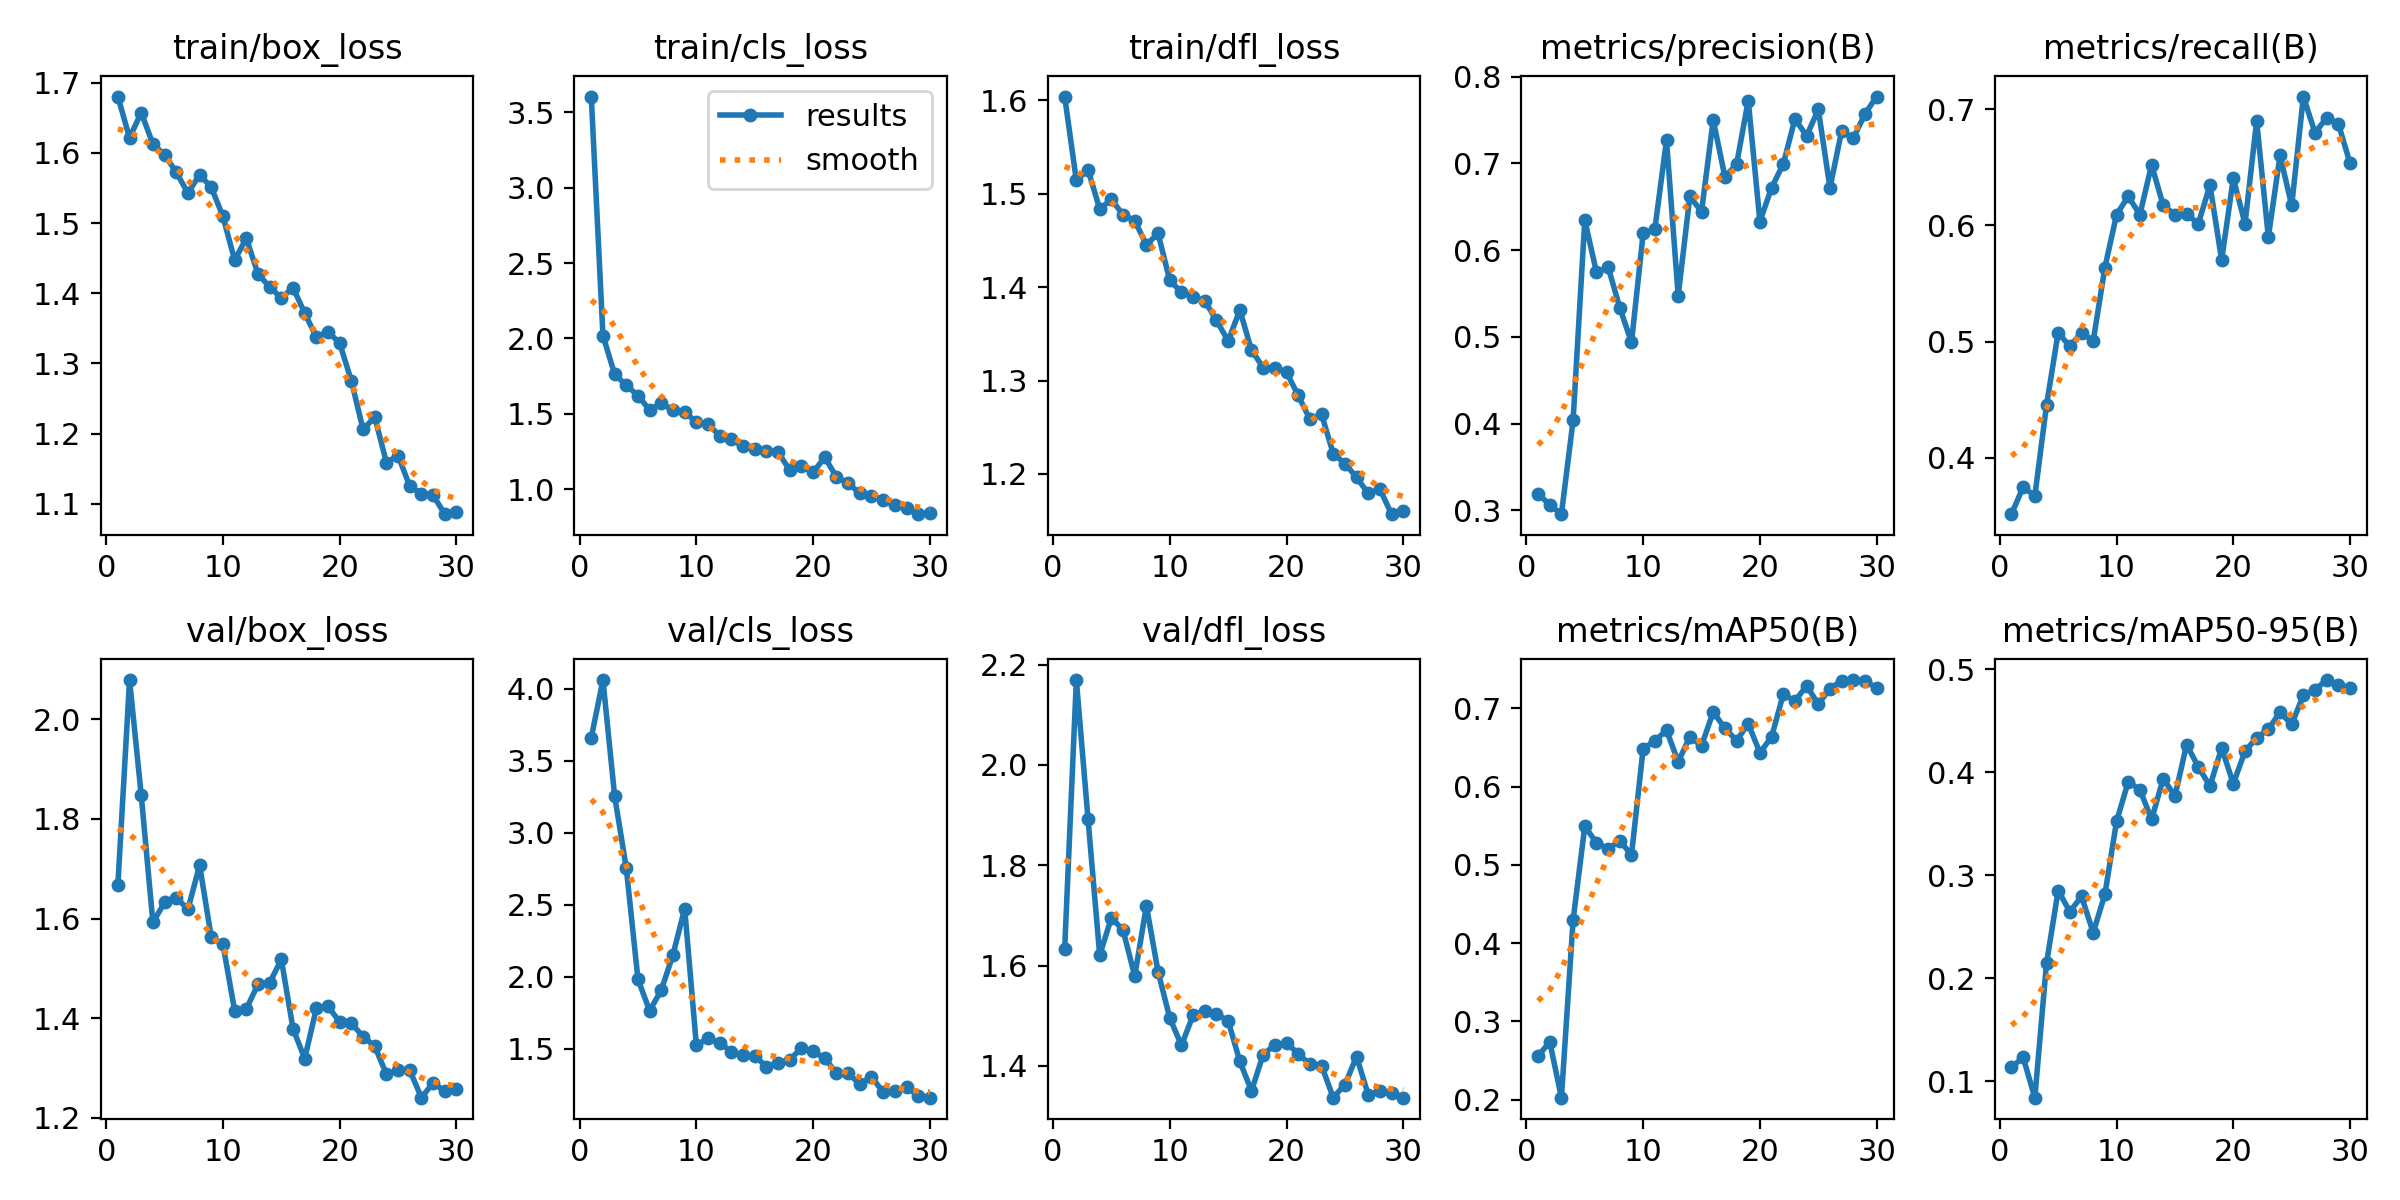

confusion_matrix.png


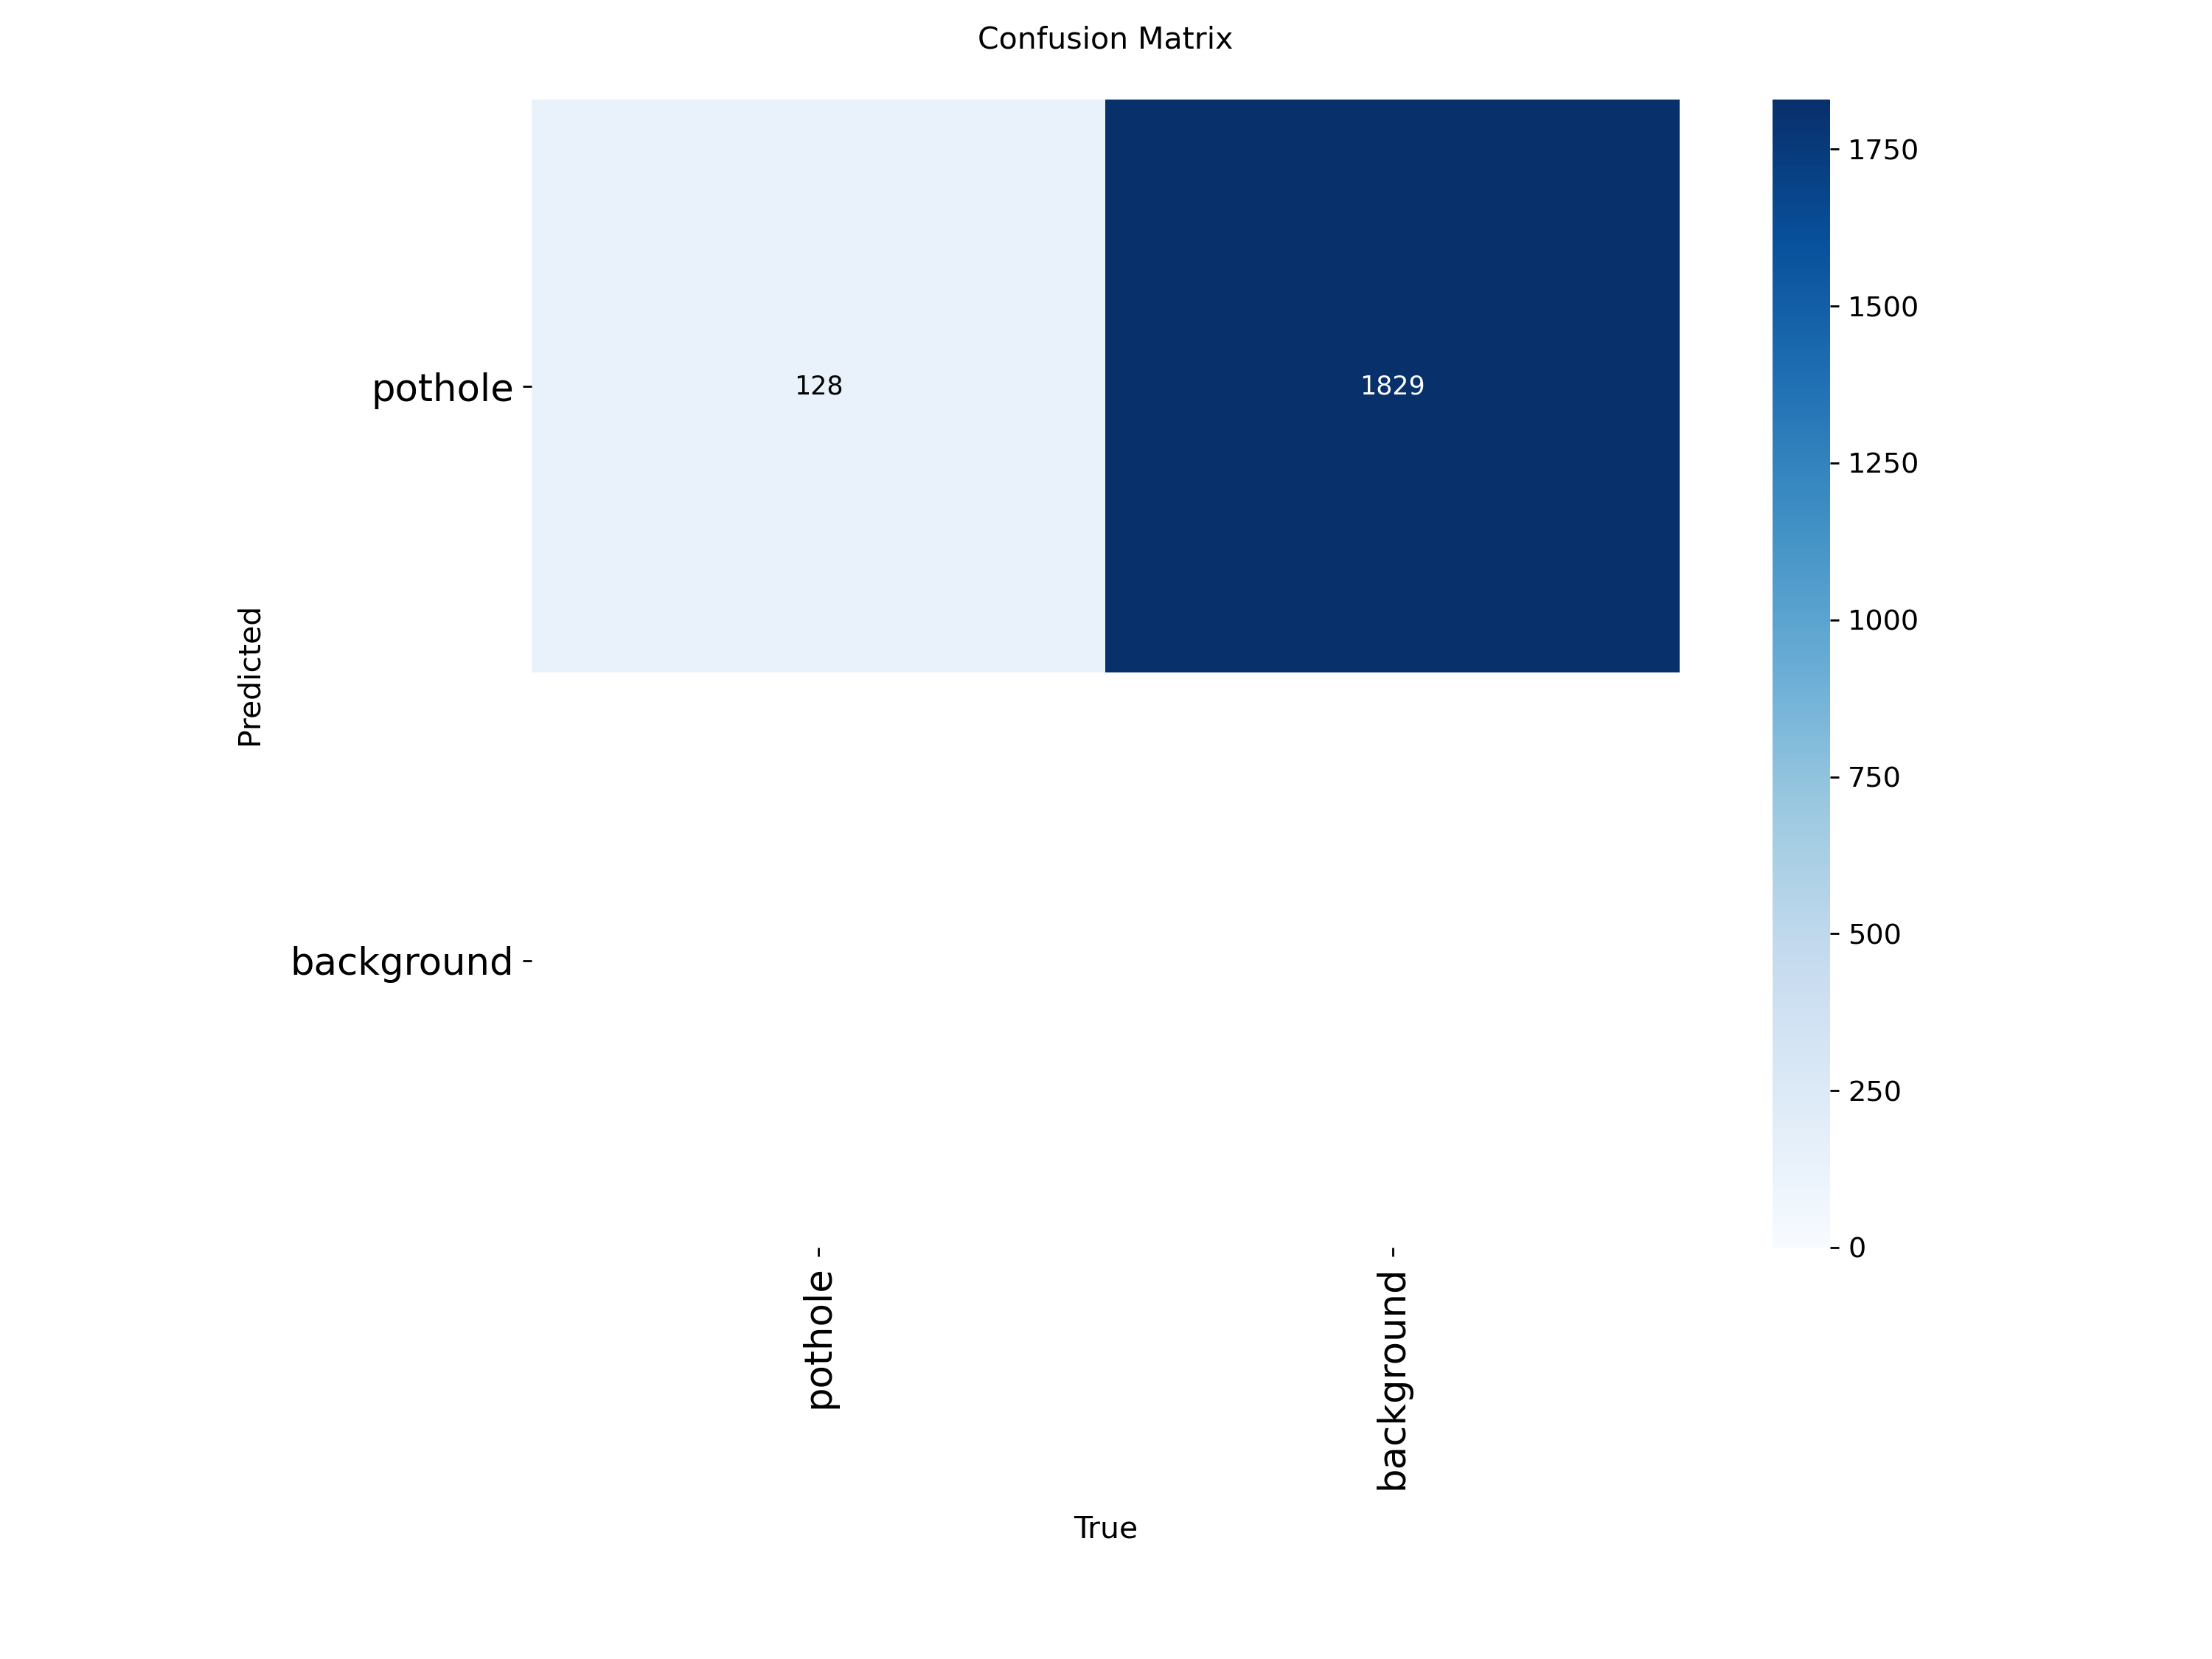

In [19]:
from IPython.display import display, Image
from pathlib import Path

RUN_DIR = Path(
    "/content/streetguard_runs/streetguard_yolo11n"
)

for filename in ["results.png", "confusion_matrix.png"]:
    path = RUN_DIR / filename

    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print(f"Not found: {filename}")

In [20]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

MODEL_PATH = (
    "/content/drive/MyDrive/YOLO StreetGuard AI/"
    "models/streetguard_yolo11n_best.pt"
)

DATA_YAML = "/content/streetguard_dataset/potholes/data.yaml"

model = YOLO(MODEL_PATH)

metrics = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    save_json=True,
    project="/content/streetguard_runs",
    name="streetguard_validation_review"
)

print("\nVALIDATION RESULTS")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

print("\nReview files in:")
print("/content/streetguard_runs/streetguard_validation_review")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3117.8±1020.6 MB/s, size: 110.4 KB)
val: Scanning /content/streetguard_dataset/potholes/labels/val.cache... 52 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 8.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.8it/s 1.5s
                   all         52        128      0.725       0.68      0.728      0.486
Speed: 2.7ms preprocess, 8.3ms inference, 0.0ms loss, 2.3ms postprocess per image
Saving /content/streetguard_runs/streetguard_validation_review/predictions.json...

Evaluating faster-coco-eval mAP...
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 318ms
Prepared 1 p

In [21]:
from pathlib import Path

output_dir = Path(
    "/content/streetguard_runs/streetguard_validation_review"
)

for path in sorted(output_dir.rglob("*")):
    if path.is_file():
        print(path.name)

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
predictions.json
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg



val_batch0_labels.jpg


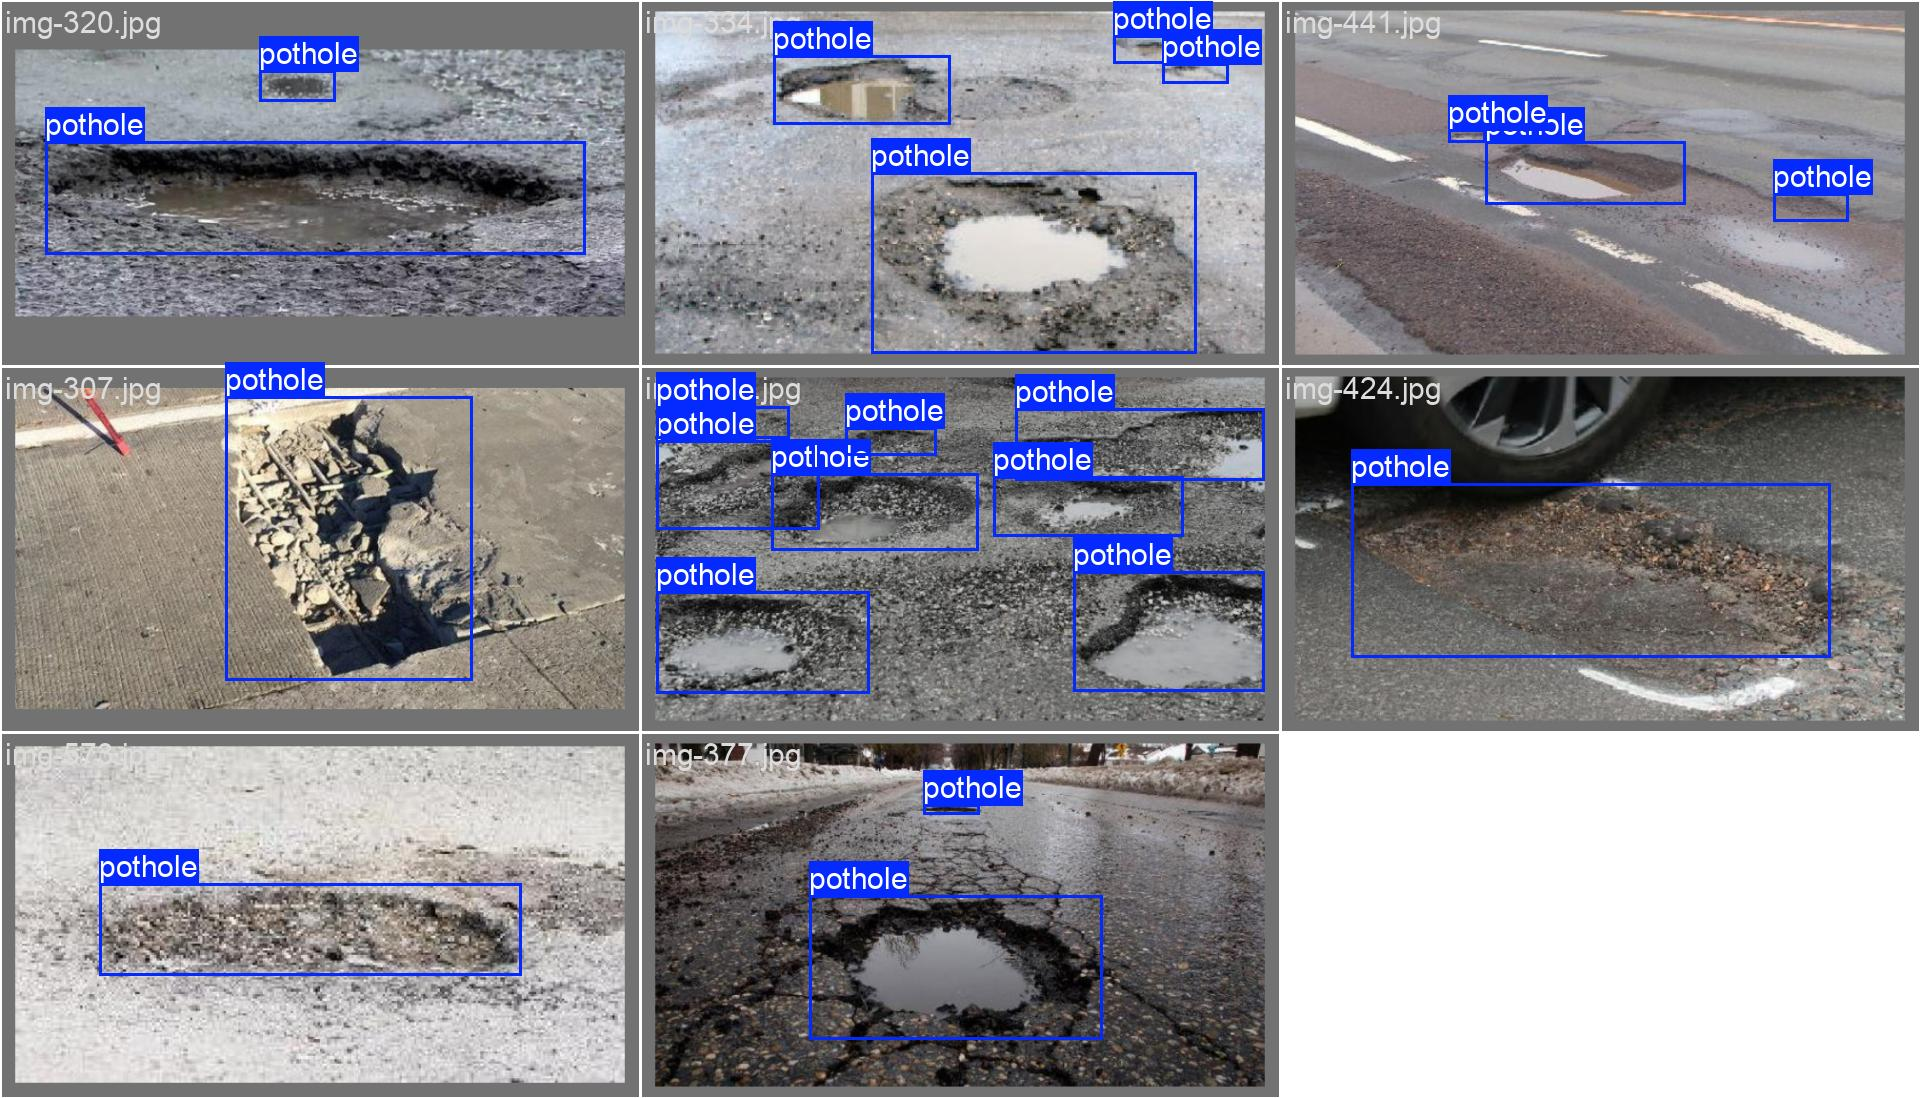


val_batch0_pred.jpg


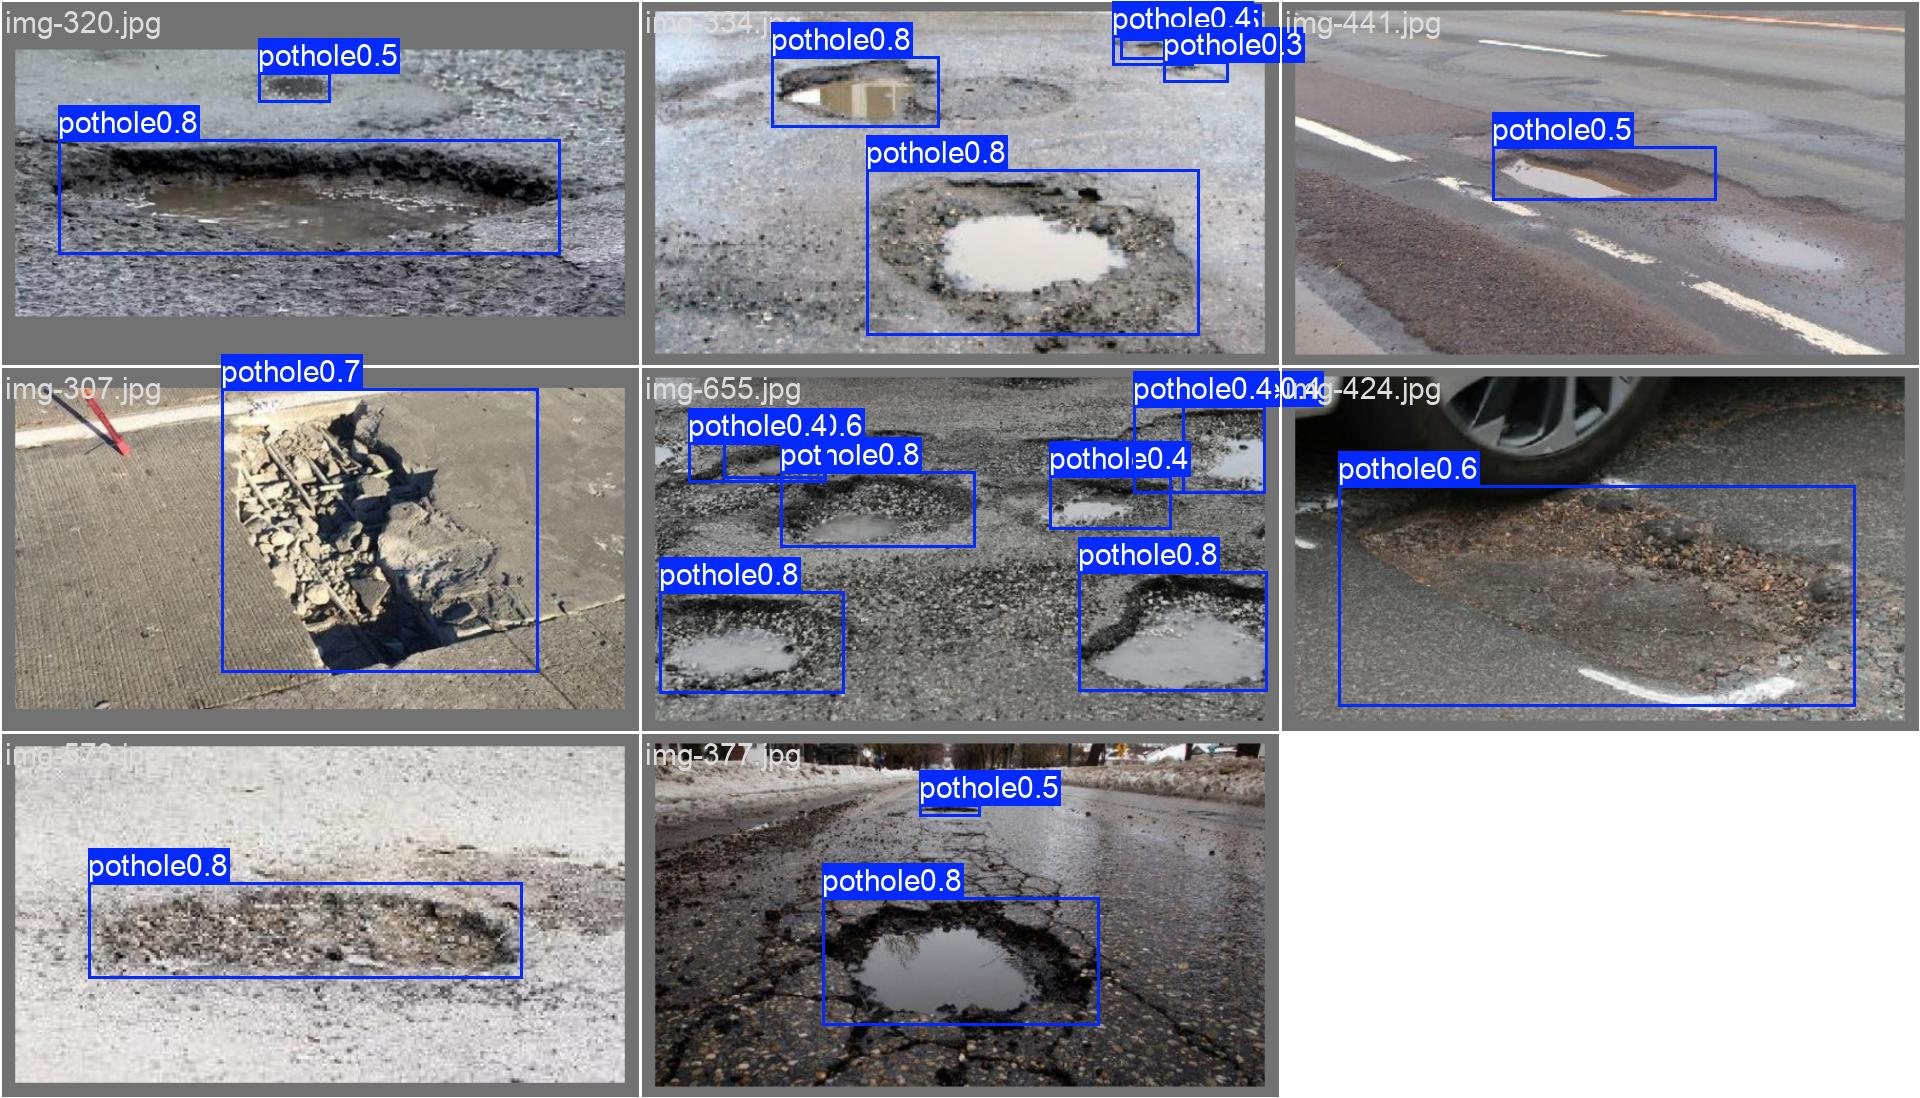


val_batch1_labels.jpg


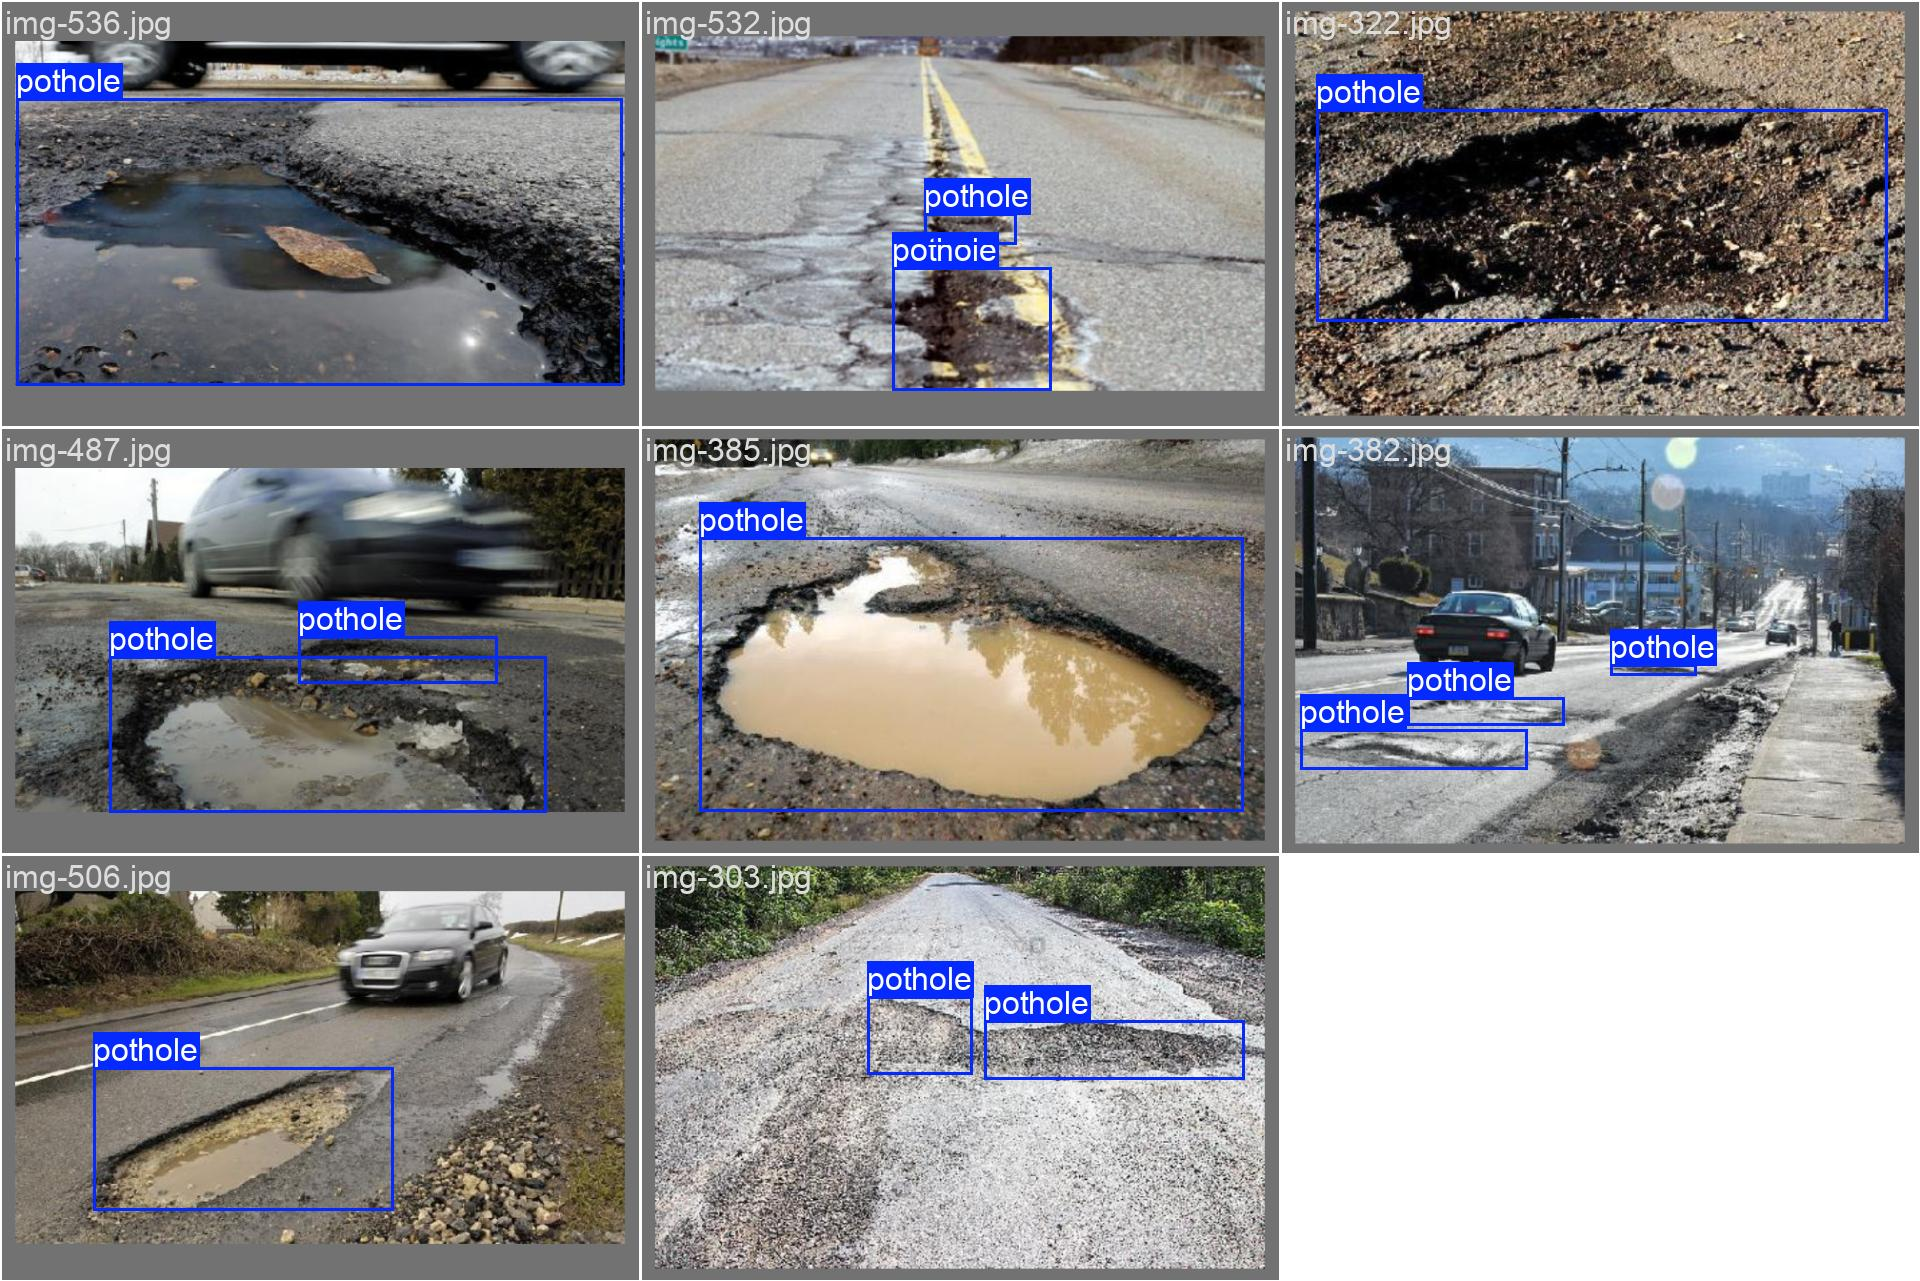


val_batch1_pred.jpg


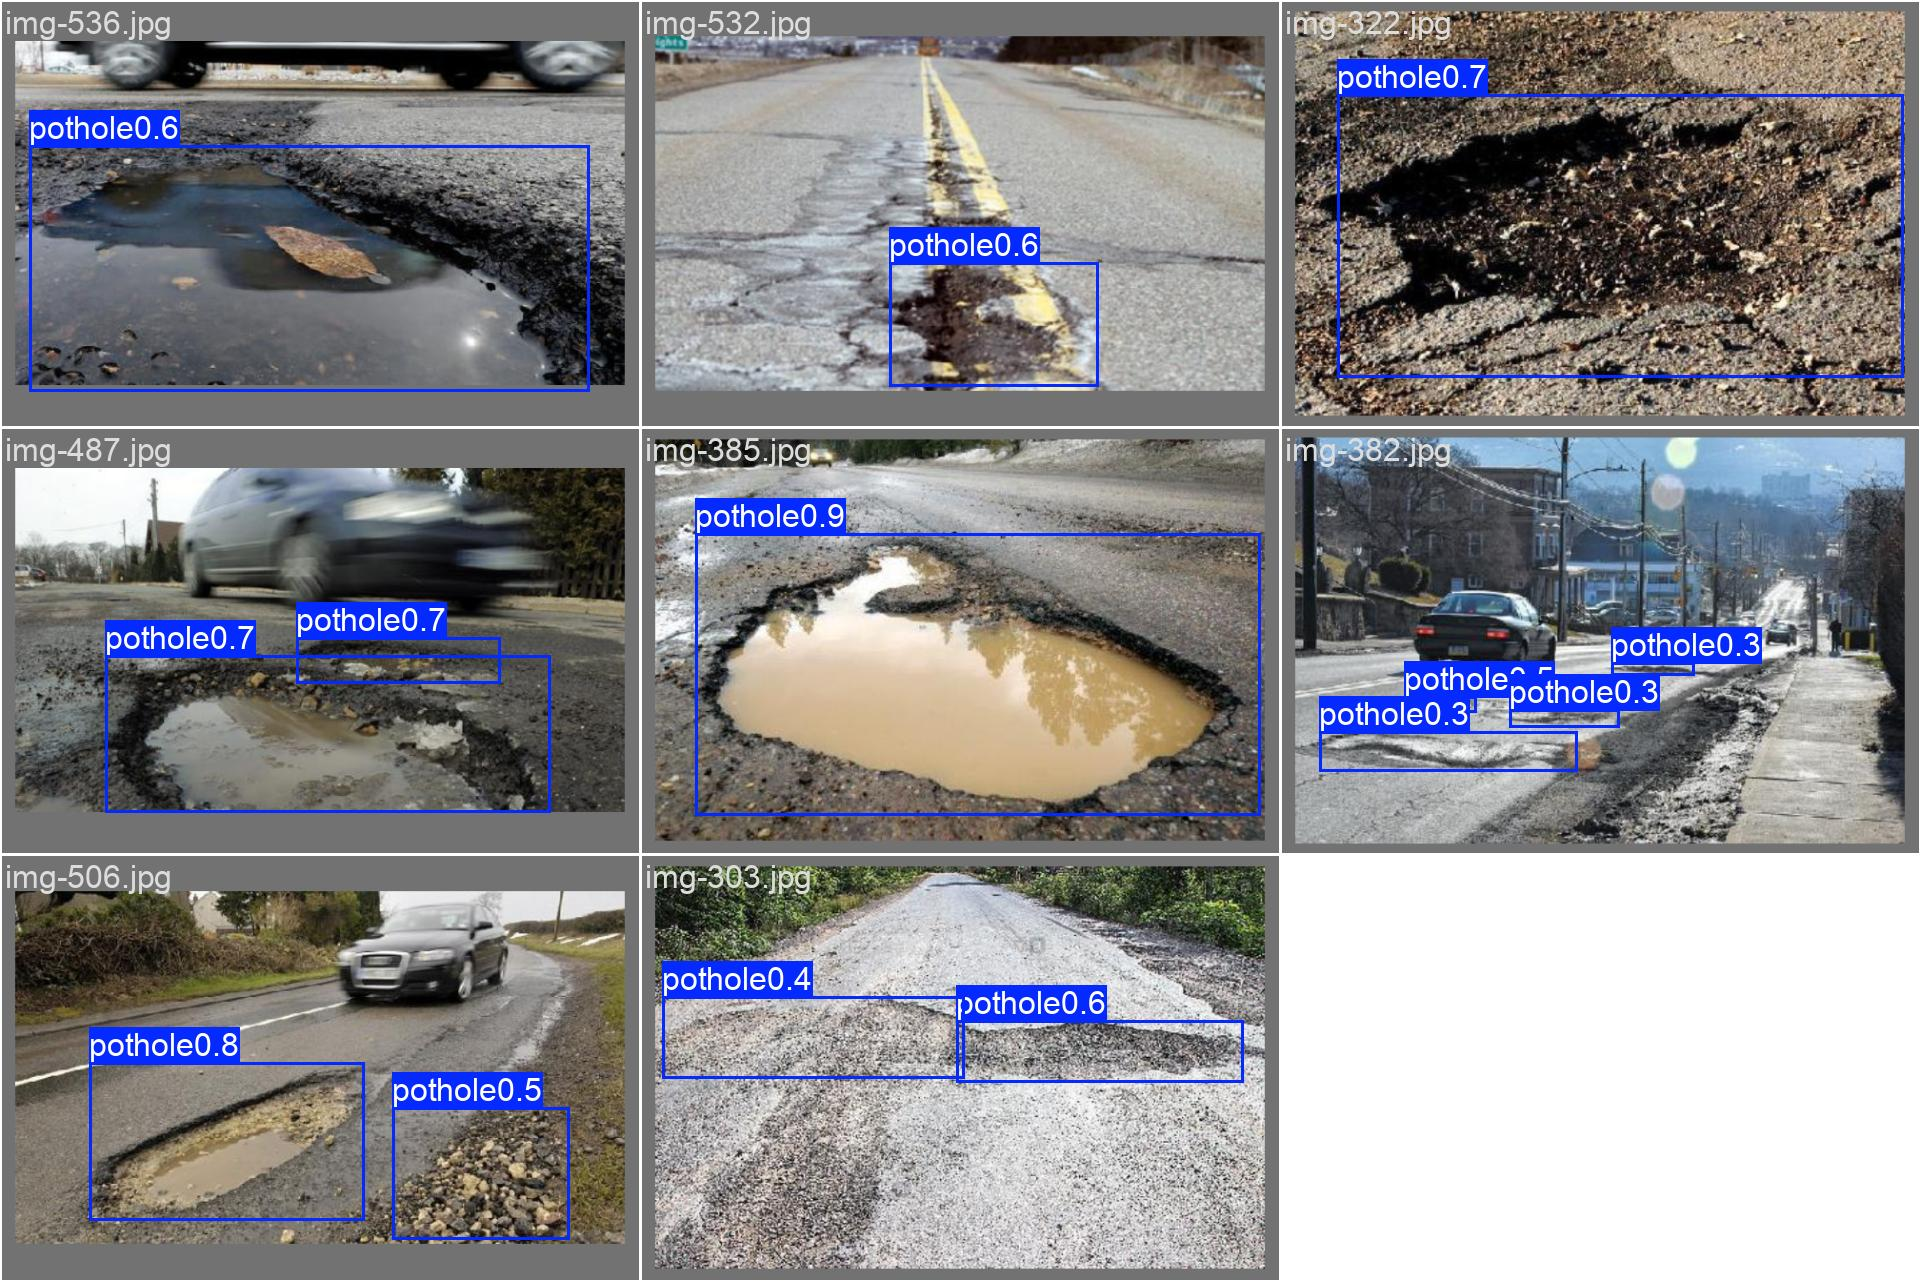


confusion_matrix_normalized.png


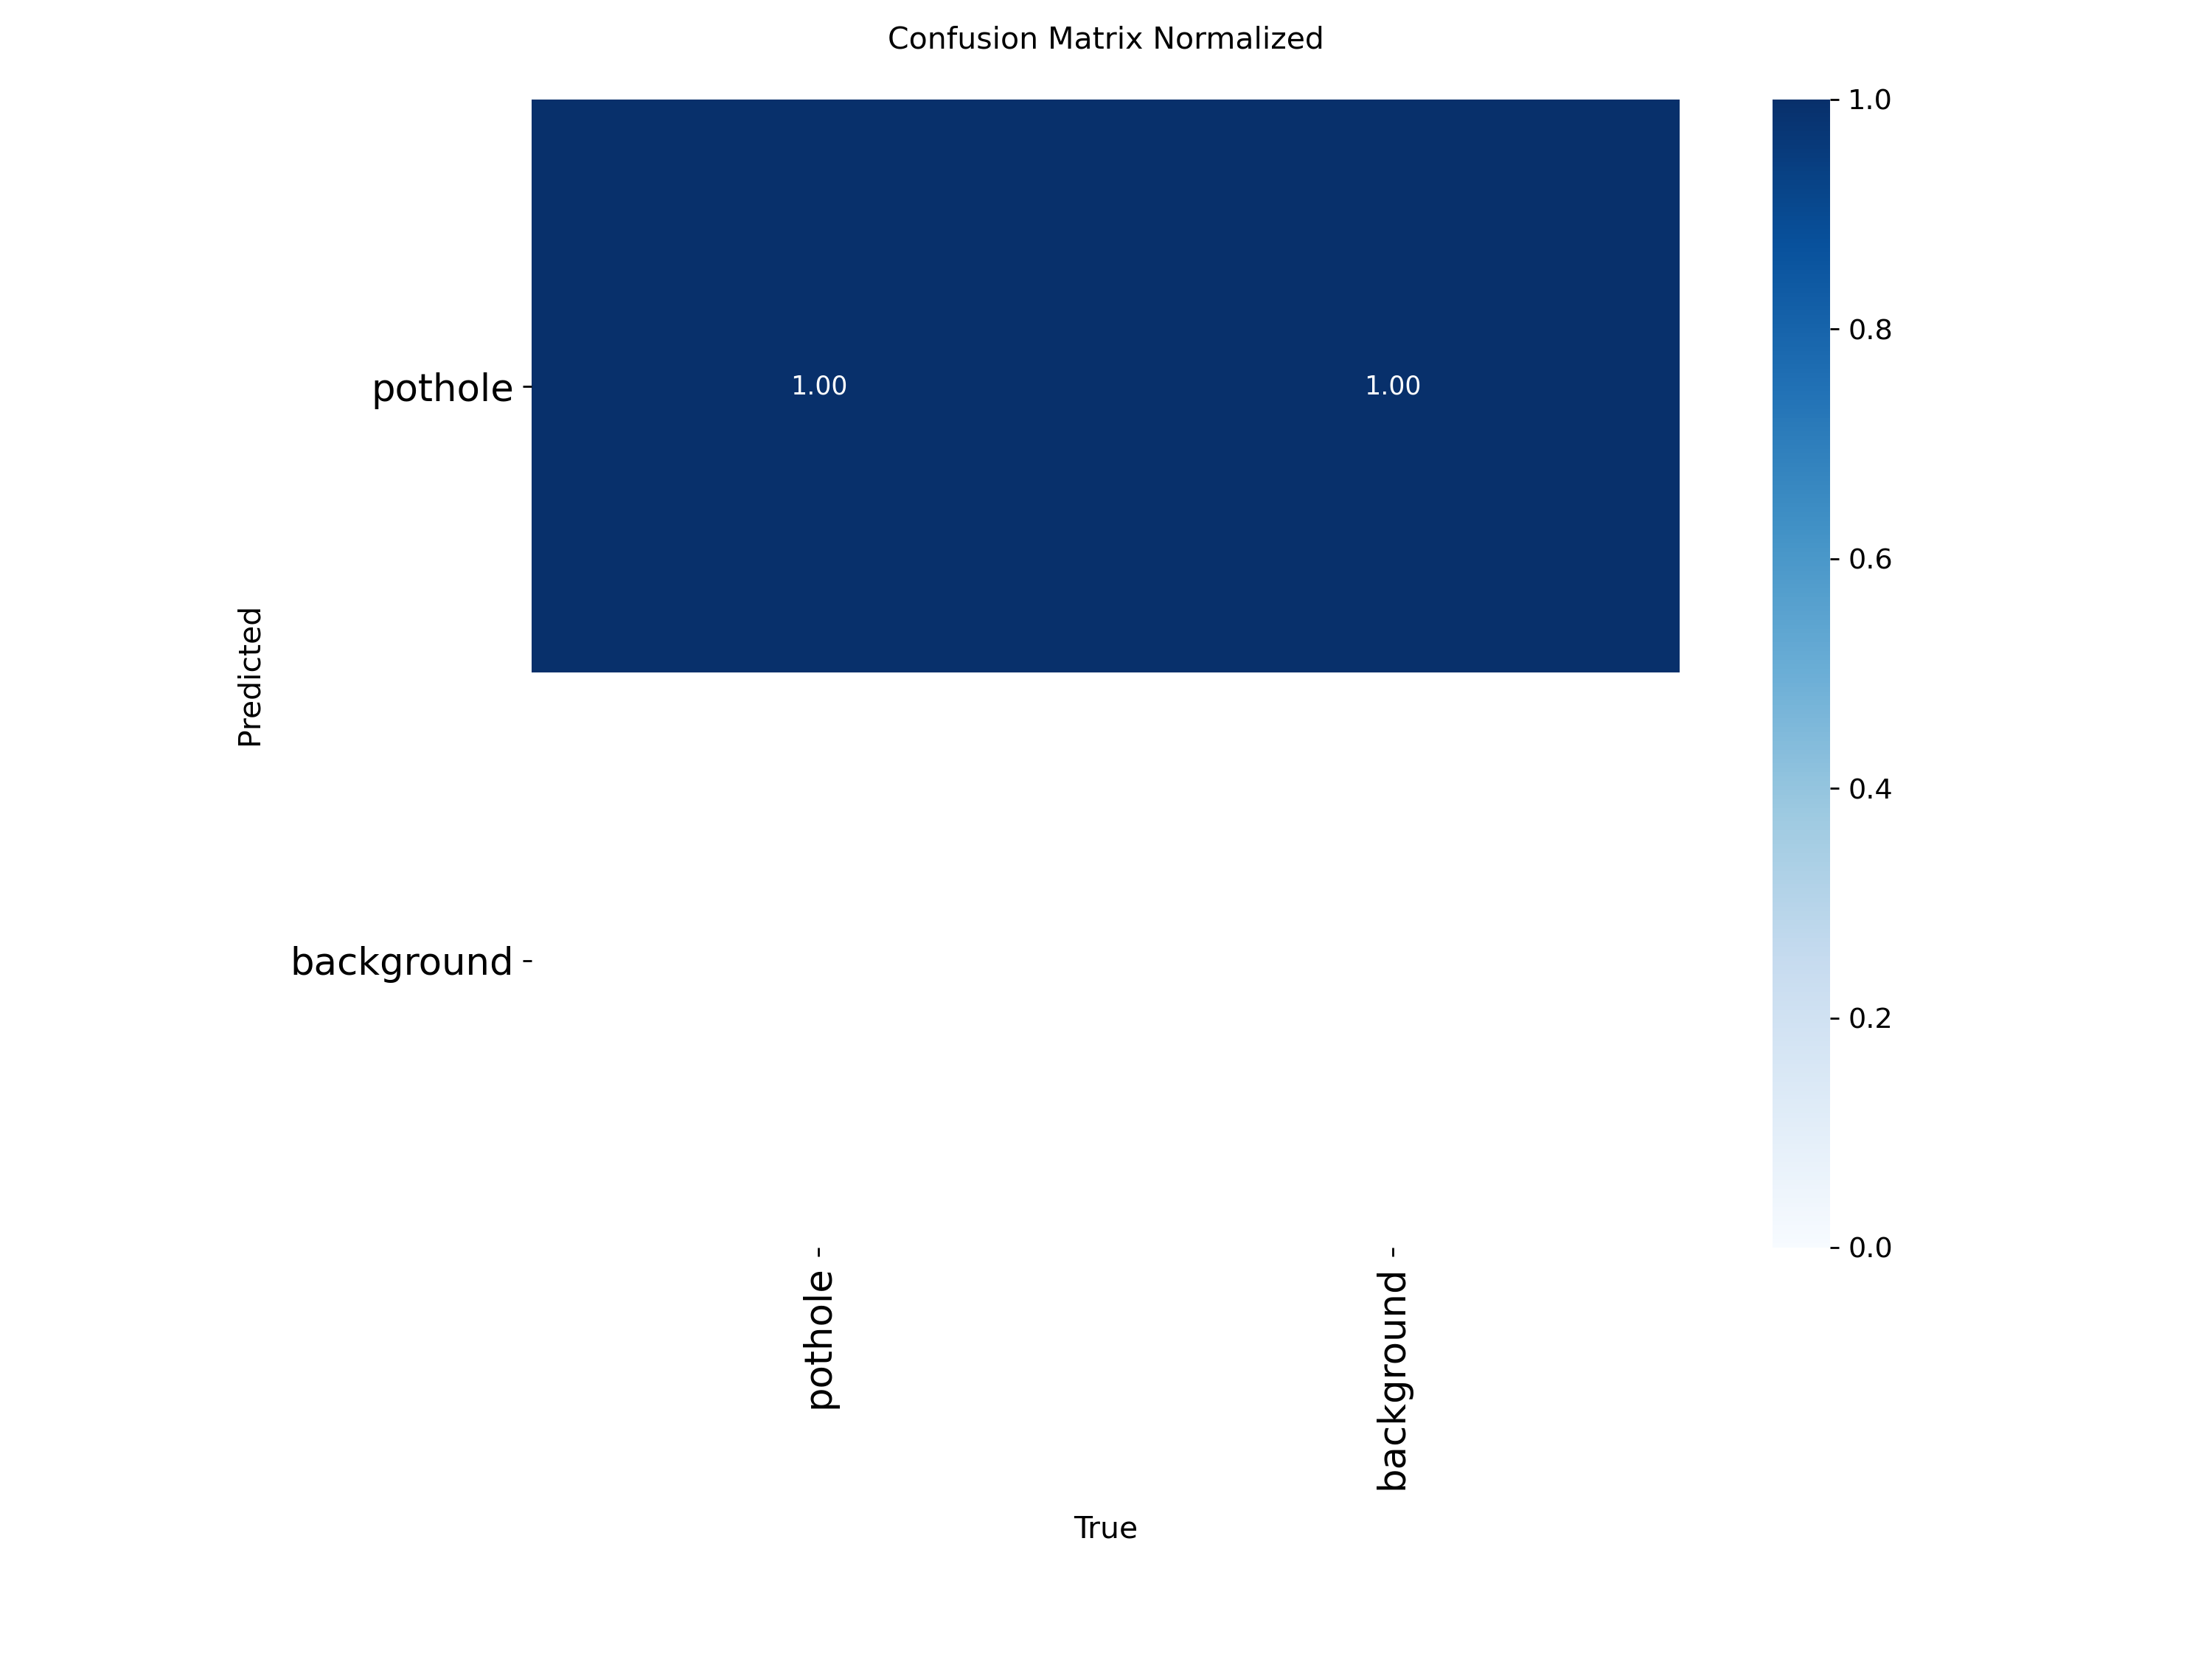


BoxPR_curve.png


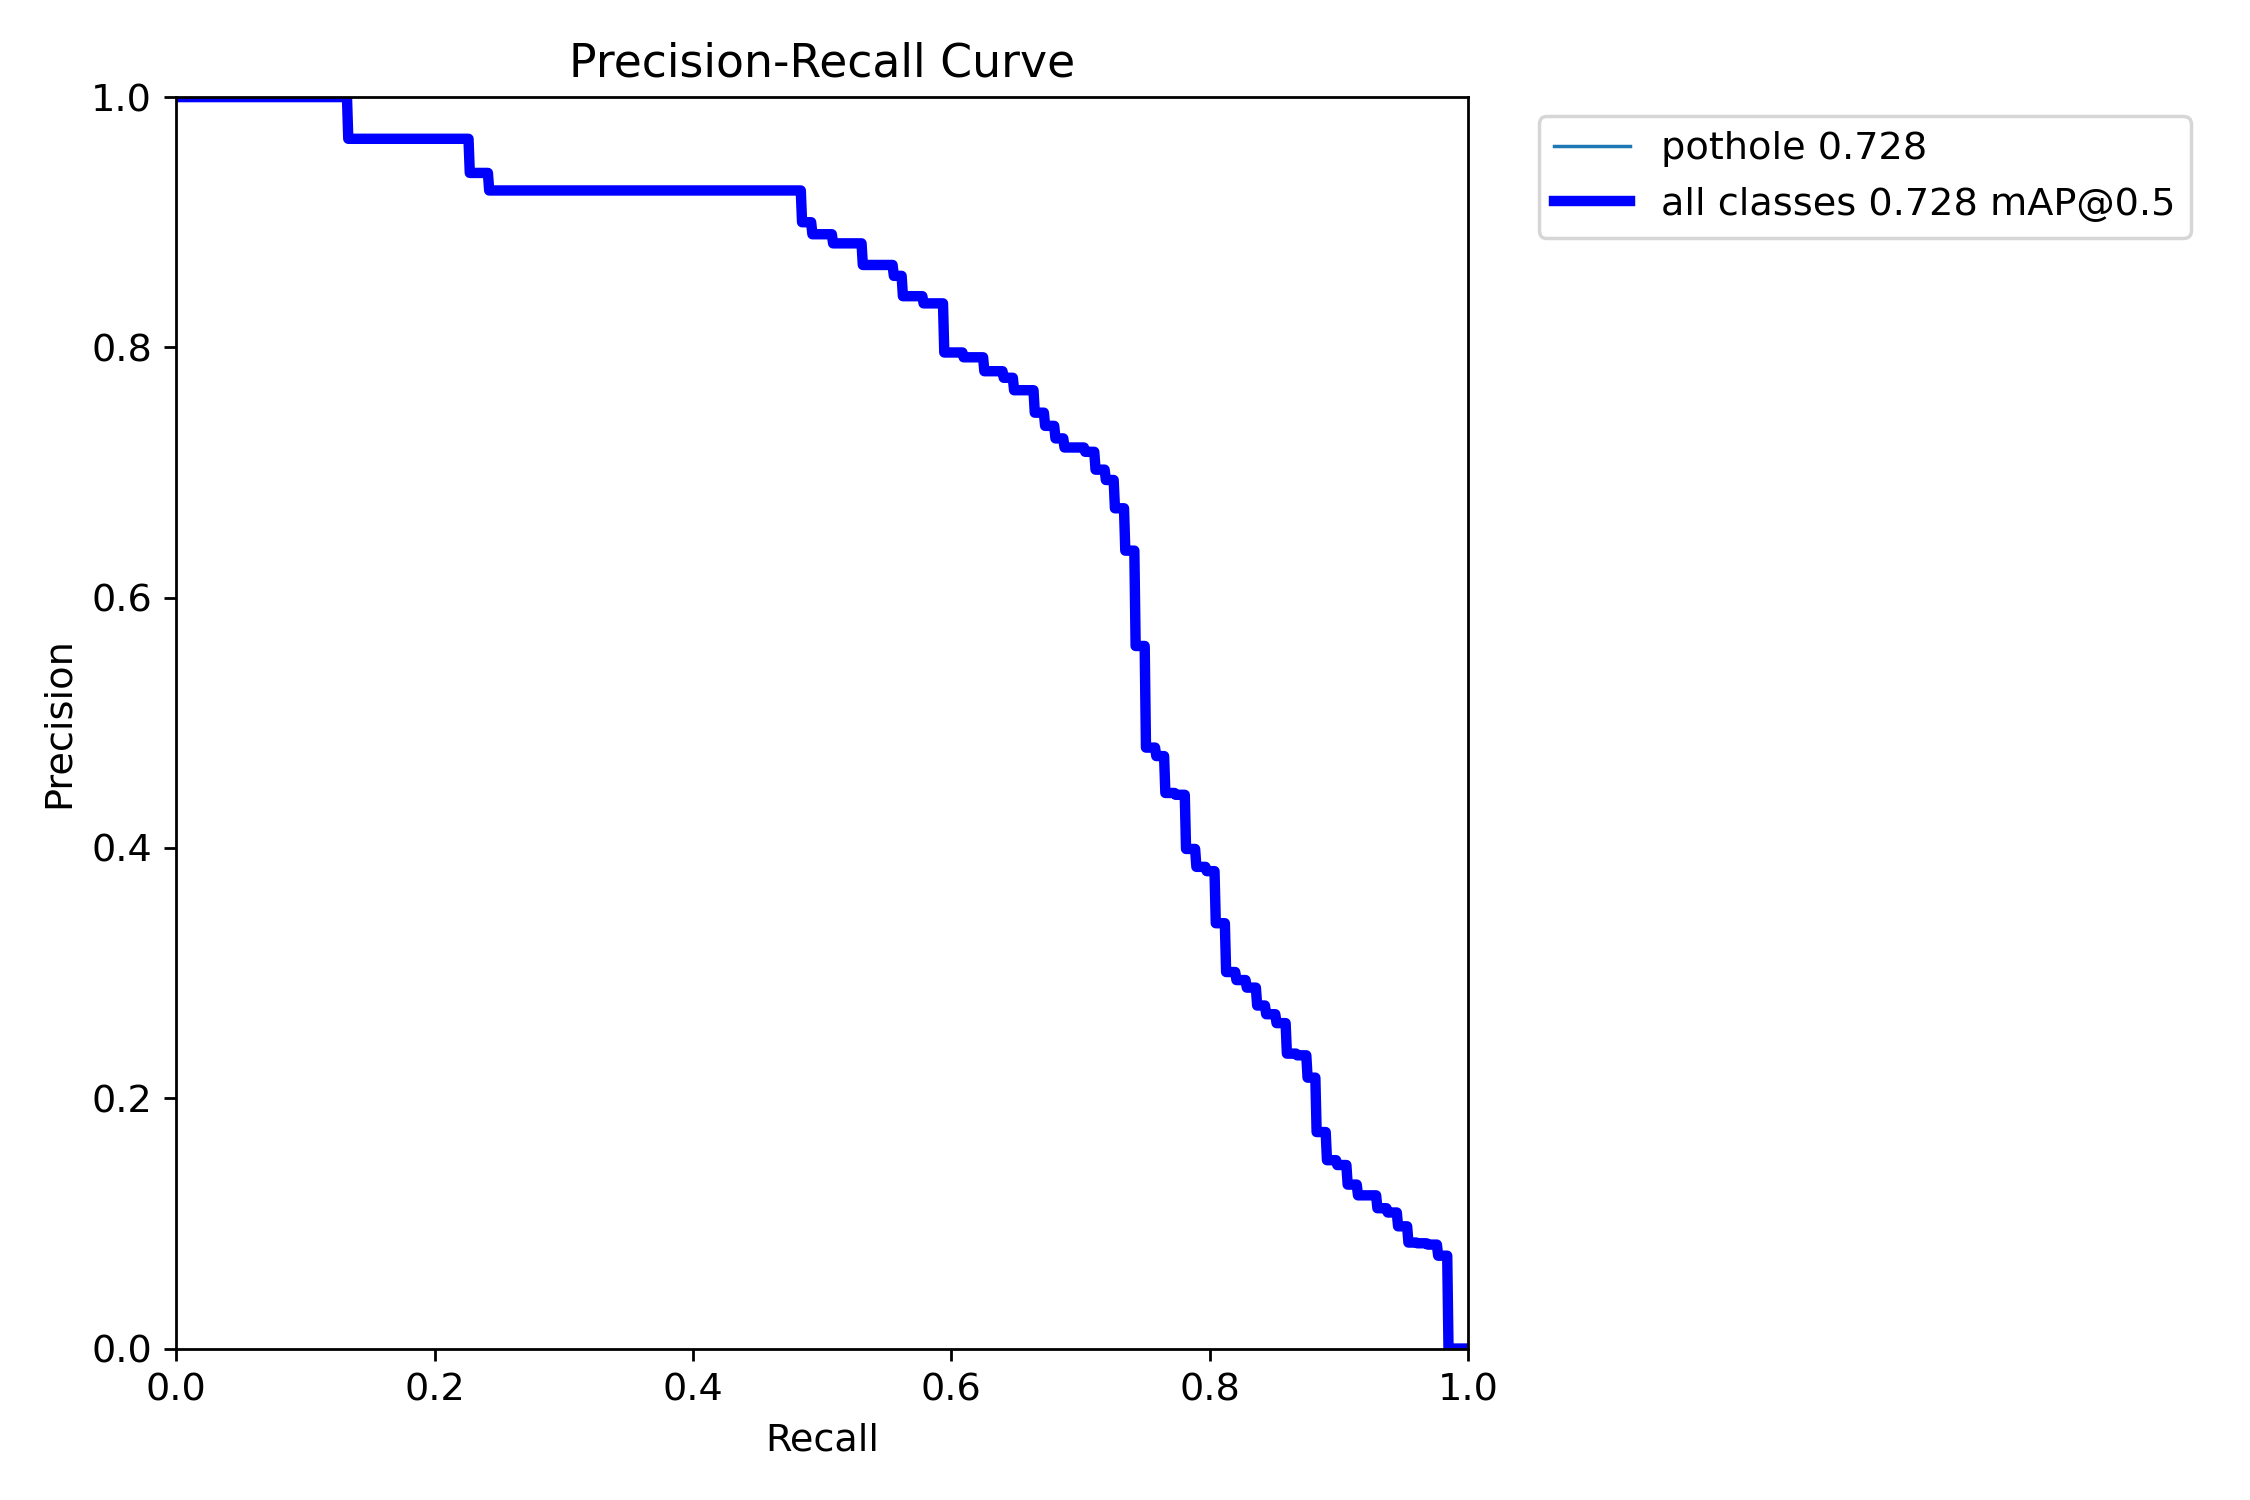


BoxF1_curve.png


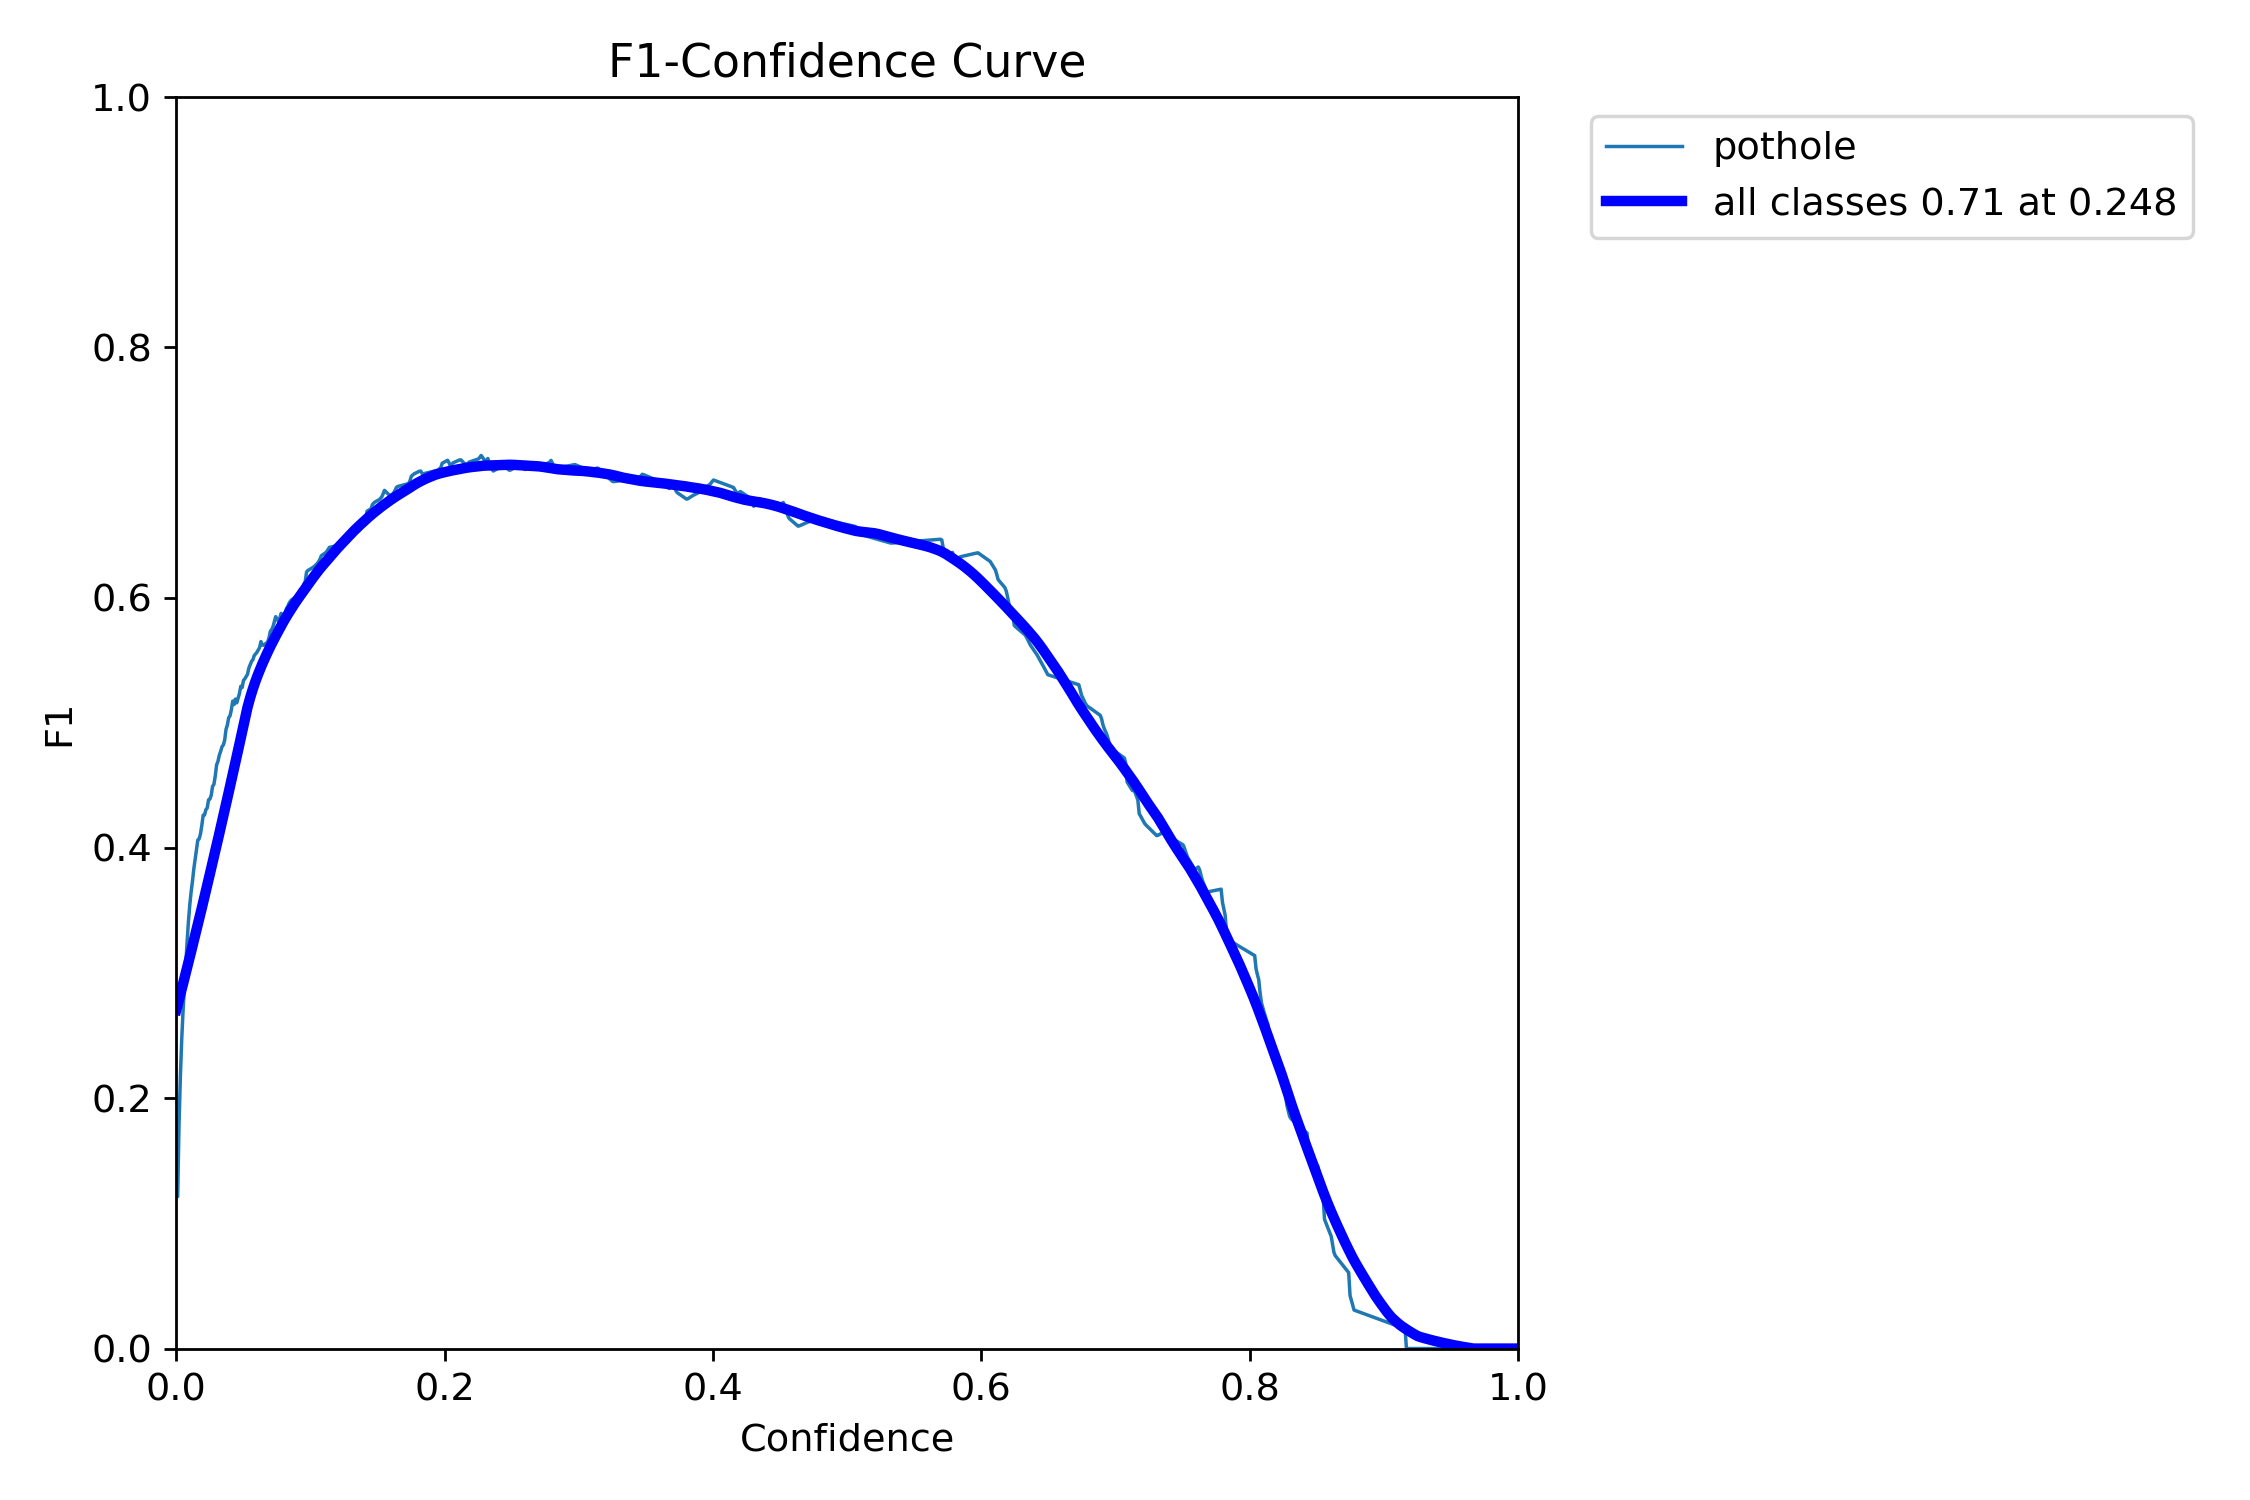

In [22]:
from pathlib import Path
from IPython.display import display, Image

OUTPUT_DIR = Path(
    "/content/streetguard_runs/streetguard_validation_review"
)

files_to_display = [
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
]

for filename in files_to_display:
    file_path = OUTPUT_DIR / filename

    if file_path.exists():
        print(f"\n{filename}")
        display(Image(filename=str(file_path)))
    else:
        print(f"File not found: {file_path}")

In [23]:
from pathlib import Path

runs_dir = Path("/content/streetguard_runs")

for model_path in runs_dir.glob("**/weights/best.pt"):
    print(f"Found best model: {model_path}")
    print(f"Model size: {model_path.stat().st_size / (1024 * 1024):.2f} MB")

Found best model: /content/streetguard_runs/streetguard_yolo11n/weights/best.pt
Model size: 5.25 MB


In [25]:
from pathlib import Path

search_dirs = [
    Path("/content/streetguard_runs"),
    Path("/content/runs"),
]

found_models = []

for directory in search_dirs:
    if directory.exists():
        found_models.extend(directory.rglob("best.pt"))

if found_models:
    print("Trained model(s) found:\n")

    for model in found_models:
        print(f"Path: {model}")
        print(f"Size: {model.stat().st_size / (1024 * 1024):.2f} MB")
        print("-" * 50)
else:
    print("No best.pt file found in the expected directories.")
    print("\nFolders currently available in /content:")
    for item in Path("/content").iterdir():
        print(item)

Trained model(s) found:

Path: /content/streetguard_runs/streetguard_yolo11n/weights/best.pt
Size: 5.25 MB
--------------------------------------------------


In [26]:
from google.colab import files
from pathlib import Path

search_dirs = [
    Path("/content/streetguard_runs"),
    Path("/content/runs"),
]

models = []

for directory in search_dirs:
    if directory.exists():
        models.extend(directory.rglob("best.pt"))

if models:
    model_path = models[0]
    print(f"Downloading: {model_path}")
    files.download(str(model_path))
else:
    print("No best.pt file found. Run Step 1 and share its output.")

Downloading: /content/streetguard_runs/streetguard_yolo11n/weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>